In [2]:
# Import the libraries we will use for data analysis and deep learning

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
from google.colab import files
uploaded = files.upload()

Saving pcap.parquet to pcap.parquet


In [4]:
# Load the PCAP dataset
df = pd.read_parquet("pcap.parquet")
print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (455641, 42)


In [5]:
# Display all column names
print("Column names:")
print(df.columns.tolist())

Column names:
['Header_Length', 'Protocol Type', 'Time_To_Live', 'Rate', 'fin_flag_number', 'syn_flag_number', 'rst_flag_number', 'psh_flag_number', 'ack_flag_number', 'ece_flag_number', 'cwr_flag_number', 'ack_count', 'syn_count', 'fin_count', 'rst_count', 'HTTP', 'HTTPS', 'DNS', 'Telnet', 'SMTP', 'SSH', 'IRC', 'TCP', 'UDP', 'DHCP', 'ARP', 'ICMP', 'IGMP', 'IPv', 'LLC', 'Tot sum', 'Min', 'Max', 'AVG', 'Std', 'Tot size', 'IAT', 'Number', 'Variance', 'Hash', 'MalwareFamily', 'Arch']


In [6]:
# Display the first five rows of the dataset
df.head()

,Header_Length,Protocol Type,Time_To_Live,Rate,fin_flag_number,syn_flag_number,rst_flag_number,psh_flag_number,ack_flag_number,ece_flag_number,...,Max,AVG,Std,Tot size,IAT,Number,Variance,Hash,MalwareFamily,Arch
0,7.2,17,61.2,8.706623,0.0,0.0,0.0,0.0,0.0,0.0,...,342,168.4,120.106619,168.4,0.114855,10,14425.600000,85f4c8ed3d1640f8b9ddc5722b225eaf4e75f78d43b7a3...,Benign,x86
1,4.8,17,64.0,6.182197,0.0,0.0,0.0,0.0,0.0,0.0,...,342,103.0,85.120829,103.0,0.213177,10,7245.555556,85f4c8ed3d1640f8b9ddc5722b225eaf4e75f78d43b7a3...,Benign,x86
2,4.8,17,51.2,4.553498,0.0,0.0,0.0,0.0,0.0,0.0,...,342,176.4,143.501607,176.4,0.219616,10,20592.711111,85f4c8ed3d1640f8b9ddc5722b225eaf4e75f78d43b7a3...,Benign,x86
3,3.2,1,51.2,5.793830,0.0,0.0,0.0,0.0,0.0,0.0,...,342,98.6,87.823307,98.6,0.172604,10,7712.933333,85f4c8ed3d1640f8b9ddc5722b225eaf4e75f78d43b7a3...,Benign,x86
4,5.6,17,64.0,3.760603,0.0,0.0,0.0,0.0,0.0,0.0,...,342,155.8,129.070007,155.8,0.269501,10,16659.066667,85f4c8ed3d1640f8b9ddc5722b225eaf4e75f78d43b7a3...,Benign,x86


In [7]:
# Check the different malware families in the dataset
print(df["MalwareFamily"].value_counts())

MalwareFamily
Mirai        319808
Benign        82622
Unknown       31531
DarkNexus      9938
Gafgyt         7666
Generic        4076
Name: count, dtype: int64


In [8]:
# Check how many missing values are present in each column
missing_values = df.isnull().sum()
print(missing_values)

Header_Length        0
Protocol Type        0
Time_To_Live         0
Rate                 0
fin_flag_number      0
syn_flag_number      0
rst_flag_number      0
psh_flag_number      0
ack_flag_number      0
ece_flag_number      0
cwr_flag_number      0
ack_count            0
syn_count            0
fin_count            0
rst_count            0
HTTP                 0
HTTPS                0
DNS                  0
Telnet               0
SMTP                 0
SSH                  0
IRC                  0
TCP                  0
UDP                  0
DHCP                 0
ARP                  0
ICMP                 0
IGMP                 0
IPv                  0
LLC                  0
Tot sum              0
Min                  0
Max                  0
AVG                  0
Std                483
Tot size             0
IAT                  0
Number               0
Variance           483
Hash                 0
MalwareFamily        0
Arch                 0
dtype: int64


In [9]:
# Check the data type of each column
print(df.dtypes)

Header_Length      float64
Protocol Type        int64
Time_To_Live       float64
Rate               float64
fin_flag_number    float64
syn_flag_number    float64
rst_flag_number    float64
psh_flag_number    float64
ack_flag_number    float64
ece_flag_number    float64
cwr_flag_number    float64
ack_count            int64
syn_count            int64
fin_count            int64
rst_count            int64
HTTP               float64
HTTPS              float64
DNS                float64
Telnet             float64
SMTP               float64
SSH                float64
IRC                float64
TCP                float64
UDP                float64
DHCP               float64
ARP                float64
ICMP               float64
IGMP               float64
IPv                float64
LLC                float64
Tot sum              int64
Min                  int64
Max                  int64
AVG                float64
Std                float64
Tot size           float64
IAT                float64
N

In [10]:
# Remove rows where the malware family is unknown
df = df[df["MalwareFamily"] != "Unknown"]
print("Unknown labels removed.")
print("New shape:", df.shape)

Unknown labels removed.
New shape: (424110, 42)


In [11]:
# Remove columns that are not useful for our prediction model
df = df.drop(["Hash", "Arch"], axis=1)
print("Hash and Arch columns removed.")
print("New shape:", df.shape)

Hash and Arch columns removed.
New shape: (424110, 40)


In [12]:
# Fill missing values in numerical columns with the median value
df["Std"] = df["Std"].fillna(df["Std"].median())
df["Variance"] = df["Variance"].fillna(df["Variance"].median())
print("Missing values handled.")

Missing values handled.


In [13]:
# Check the dataset after cleaning
print("Missing values after cleaning:")
print(df.isnull().sum().sum())
print("\nFinal shape:")
print(df.shape)

Missing values after cleaning:
0

Final shape:
(424110, 40)


In [14]:
# Count the number of samples for each malware family
malware_counts = df["MalwareFamily"].value_counts()
print(malware_counts)

MalwareFamily
Mirai        319808
Benign        82622
DarkNexus      9938
Gafgyt         7666
Generic        4076
Name: count, dtype: int64


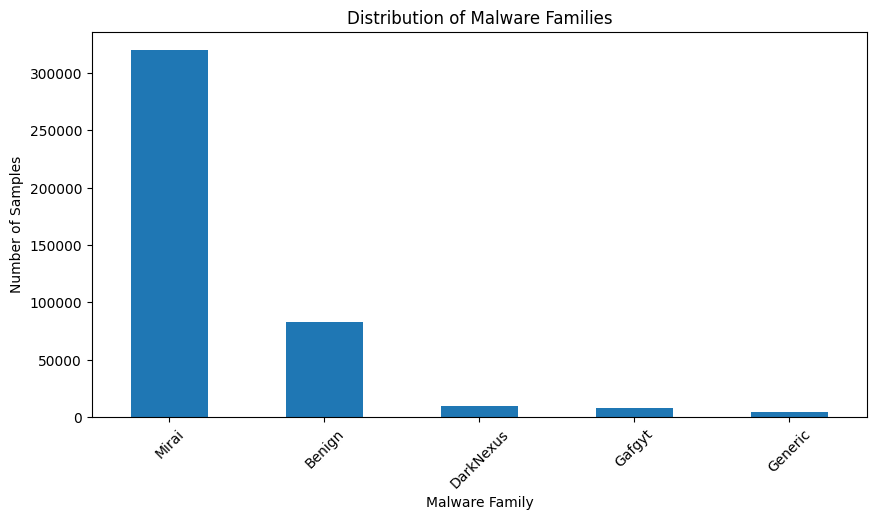

In [15]:
# Plot the number of samples for each malware family
plt.figure(figsize=(10, 5))
malware_counts.plot(kind="bar")
plt.title("Distribution of Malware Families")
plt.xlabel("Malware Family")
plt.ylabel("Number of Samples")
plt.xticks(rotation=45)
plt.show()

In [16]:
# Separate the input features from the target column
X = df.drop("MalwareFamily", axis=1)
y = df["MalwareFamily"]
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (424110, 39)
Target shape: (424110,)


In [17]:
# Convert malware family names into numerical labels
from sklearn.preprocessing import LabelEncoder
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)
print("Classes:")
print(label_encoder.classes_)

Classes:
['Benign' 'DarkNexus' 'Gafgyt' 'Generic' 'Mirai']


In [18]:
# Show the numerical label assigned to each malware family
for i, name in enumerate(label_encoder.classes_):
    print(i, "=", name)

0 = Benign
1 = DarkNexus
2 = Gafgyt
3 = Generic
4 = Mirai


In [19]:
# Split the dataset into training and testing sets
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (339288, 39)
Testing data: (84822, 39)


In [21]:
# Scale the numerical features so they have similar ranges
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print("Feature scaling completed.")

ValueError: Input X contains infinity or a value too large for dtype('float64').

In [22]:
# Check for infinite values in the training data
print("Infinite values in training data:")
print(np.isinf(X_train).sum().sum())
print("\nInfinite values in testing data:")
print(np.isinf(X_test).sum().sum())

Infinite values in training data:
378

Infinite values in testing data:
87


In [23]:
# Find columns containing infinite values
infinite_columns = X_train.columns[np.isinf(X_train).any()]
print("Columns with infinite values:")
print(infinite_columns.tolist())

Columns with infinite values:
['Rate']


In [24]:
# Replace infinite values with missing values

X_train = X_train.replace([np.inf, -np.inf], np.nan)
X_test = X_test.replace([np.inf, -np.inf], np.nan)

print("Infinite values replaced.")

Infinite values replaced.


In [25]:
# Fill missing values using the training data median
train_medians = X_train.median()
X_train = X_train.fillna(train_medians)
X_test = X_test.fillna(train_medians)
print("Missing values filled.")

Missing values filled.


In [26]:
# Check that no infinite or missing values remain
print("Infinite values in training:", np.isinf(X_train).sum().sum())
print("Infinite values in testing:", np.isinf(X_test).sum().sum())
print("Missing values in training:", X_train.isnull().sum().sum())
print("Missing values in testing:", X_test.isnull().sum().sum())

Infinite values in training: 0
Infinite values in testing: 0
Missing values in training: 0
Missing values in testing: 0


In [27]:
# Scale the features for the deep learning model
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print("Feature scaling completed.")
print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)

Feature scaling completed.
Training data shape: (339288, 39)
Testing data shape: (84822, 39)


In [28]:
# Calculate weights for the different malware classes
from sklearn.utils.class_weight import compute_class_weight
classes = np.unique(y_train)
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = dict(zip(classes, class_weights))
print("Class weights:")
print(class_weights)

Class weights:
{np.int64(0): np.float64(1.0266210777935791), np.int64(1): np.float64(8.53554716981132), np.int64(2): np.float64(11.064340453285505), np.int64(3): np.float64(20.80883164673413), np.int64(4): np.float64(0.265228301400061)}


In [29]:
# Import TensorFlow for building the deep learning model
import tensorflow as tf
print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [30]:
# Build a simple deep neural network

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(39,)),

    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dropout(0.2),

    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dropout(0.2),

    tf.keras.layers.Dense(5, activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         2,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,805 (18.77 KB)

 Trainable params: 4,805 (18.77 KB)

 Non-trainable params: 0 (0.00 B)

In [31]:
# Configure the model for training
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
print("Model compiled successfully!")

Model compiled successfully!


In [32]:
# Train the deep learning model

history = model.fit(
    X_train_scaled,
    y_train,
    epochs=10,
    batch_size=256,
    validation_split=0.2,
    class_weight=class_weights,
    verbose=1
)

Epoch 1/10
1061/1061 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.3730 - loss: 1.0010 - val_accuracy: 0.2947 - val_loss: 1.0120
Epoch 2/10
1061/1061 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.3698 - loss: 0.8552 - val_accuracy: 0.3868 - val_loss: 0.9299
Epoch 3/10
1061/1061 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.3853 - loss: 0.8114 - val_accuracy: 0.3263 - val_loss: 0.9894
Epoch 4/10
1061/1061 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.3864 - loss: 0.7927 - val_accuracy: 0.3358 - val_loss: 0.9687
Epoch 5/10
1061/1061 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.3832 - loss: 0.7798 - val_accuracy: 0.3400 - val_loss: 0.9502
Epoch 6/10
1061/1061 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.3798 - loss: 0.7705 - val_accuracy: 0.3475 - val_loss: 0.9946
Epoch 7/10
1061/1061 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.3767 - loss: 0.7588 - val_accuracy: 0.3450 - val_loss: 0.9627
Epoch 8/10
1061/1061 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.3737 - loss: 0.7524 - 

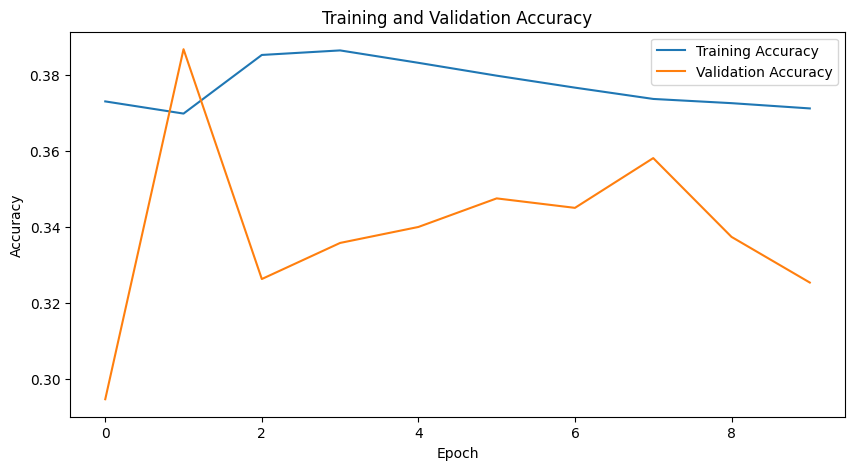

In [33]:
# Plot training and validation accuracy
plt.figure(figsize=(10, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.show()

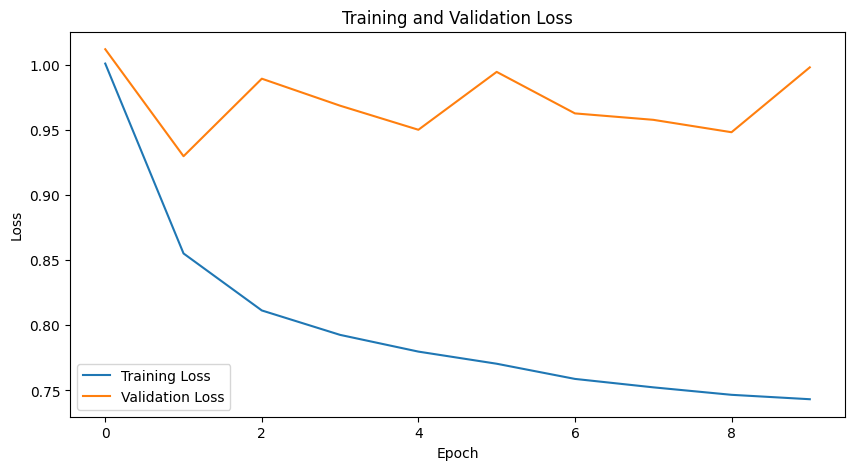

In [34]:
# Plot training and validation loss

plt.figure(figsize=(10, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.show()

In [35]:
# Evaluate the model on the unseen test data

test_loss, test_accuracy = model.evaluate(
    X_test_scaled,
    y_test,
    verbose=1
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

2651/2651 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.3272 - loss: 0.9994
Test Loss: 0.9993829727172852
Test Accuracy: 0.32721462845802307


In [36]:
# Generate predictions for the test dataset

y_pred_prob = model.predict(X_test_scaled)
y_pred = np.argmax(y_pred_prob, axis=1)
print("Predictions generated successfully.")

2651/2651 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step
Predictions generated successfully.


In [37]:
# Generate a detailed classification report
from sklearn.metrics import classification_report
print(
    classification_report(
        y_test,
        y_pred,
        target_names=label_encoder.classes_
    )
)

              precision    recall  f1-score   support

      Benign       0.90      1.00      0.94     16524
   DarkNexus       0.04      0.65      0.08      1988
      Gafgyt       0.56      0.71      0.63      1533
     Generic       0.03      0.88      0.05       815
       Mirai       0.98      0.13      0.23     63962

    accuracy                           0.33     84822
   macro avg       0.50      0.67      0.39     84822
weighted avg       0.93      0.33      0.37     84822



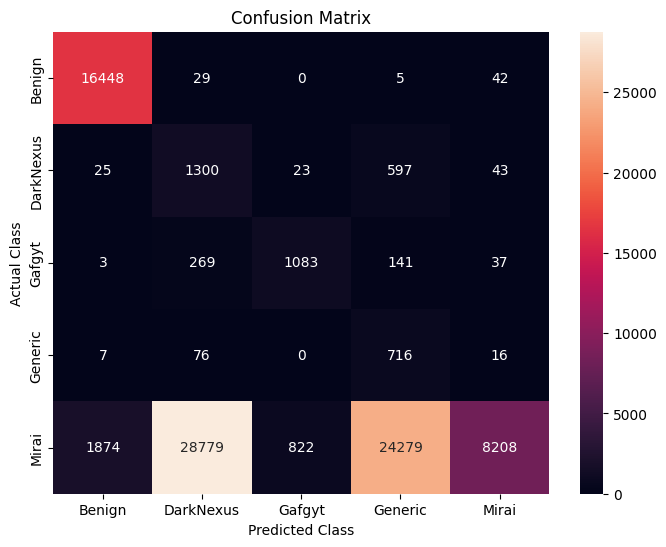

In [38]:
# Create a confusion matrix
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

In [39]:
# Convert the five classes into two classes
y_binary_train = (y_train != 0).astype(int)
y_binary_test = (y_test != 0).astype(int)
print("0 = Benign")
print("1 = Malicious")
print("\nTraining class counts:")
print(np.bincount(y_binary_train))
print("\nTesting class counts:")
print(np.bincount(y_binary_test))

0 = Benign
1 = Malicious

Training class counts:
[ 66098 273190]

Testing class counts:
[16524 68298]


In [40]:
# Calculate weights for the binary classification model
binary_classes = np.unique(y_binary_train)
binary_weights = compute_class_weight(
    class_weight="balanced",
    classes=binary_classes,
    y=y_binary_train
)
binary_class_weights = dict(zip(binary_classes, binary_weights))
print("Binary class weights:")
print(binary_class_weights)

Binary class weights:
{np.int64(0): np.float64(2.5665526944839483), np.int64(1): np.float64(0.6209744134119112)}


In [41]:
# Build the binary deep learning model
binary_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(39,)),

    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dropout(0.2),

    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dropout(0.2),

    tf.keras.layers.Dense(1, activation="sigmoid")
])

binary_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 64)             │         2,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,673 (18.25 KB)

 Trainable params: 4,673 (18.25 KB)

 Non-trainable params: 0 (0.00 B)

In [42]:
# Configure the binary classification model

binary_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)
print("Binary model compiled successfully!")

Binary model compiled successfully!


In [43]:
# Train the binary malware detection model
binary_history = binary_model.fit(
    X_train_scaled,
    y_binary_train,
    epochs=10,
    batch_size=256,
    validation_split=0.2,
    class_weight=binary_class_weights,
    verbose=1
)

Epoch 1/10
1061/1061 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.9579 - loss: 0.0955 - val_accuracy: 0.9752 - val_loss: 0.0621
Epoch 2/10
1061/1061 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9750 - loss: 0.0555 - val_accuracy: 0.9743 - val_loss: 0.0679
Epoch 3/10
1061/1061 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9763 - loss: 0.0525 - val_accuracy: 0.9789 - val_loss: 0.0571
Epoch 4/10
1061/1061 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9767 - loss: 0.0514 - val_accuracy: 0.9783 - val_loss: 0.0581
Epoch 5/10
1061/1061 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9774 - loss: 0.0491 - val_accuracy: 0.9775 - val_loss: 0.0564
Epoch 6/10
1061/1061 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9775 - loss: 0.0488 - val_accuracy: 0.9786 - val_loss: 0.0580
Epoch 7/10
1061/1061 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9779 - loss: 0.0483 - val_accuracy: 0.9778 - val_loss: 0.0596
Epoch 8/10
1061/1061 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9779 - loss: 0.0479 - 

In [44]:
# Evaluate the binary model on unseen test data

binary_test_loss, binary_test_accuracy = binary_model.evaluate(
    X_test_scaled,
    y_binary_test,
    verbose=1
)
print("Test Loss:", binary_test_loss)
print("Test Accuracy:", binary_test_accuracy)

2651/2651 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.9802 - loss: 0.0551
Test Loss: 0.055061377584934235
Test Accuracy: 0.9802055954933167


In [45]:
# Generate predictions for the test dataset
binary_pred_prob = binary_model.predict(X_test_scaled)
binary_pred = (binary_pred_prob >= 0.5).astype(int).flatten()
print("Predictions generated successfully.")

2651/2651 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step
Predictions generated successfully.


In [46]:
# Generate the classification report
from sklearn.metrics import classification_report
print(
    classification_report(
        y_binary_test,
        binary_pred,
        target_names=["Benign", "Malicious"]
    )
)

              precision    recall  f1-score   support

      Benign       0.91      0.99      0.95     16524
   Malicious       1.00      0.98      0.99     68298

    accuracy                           0.98     84822
   macro avg       0.96      0.99      0.97     84822
weighted avg       0.98      0.98      0.98     84822



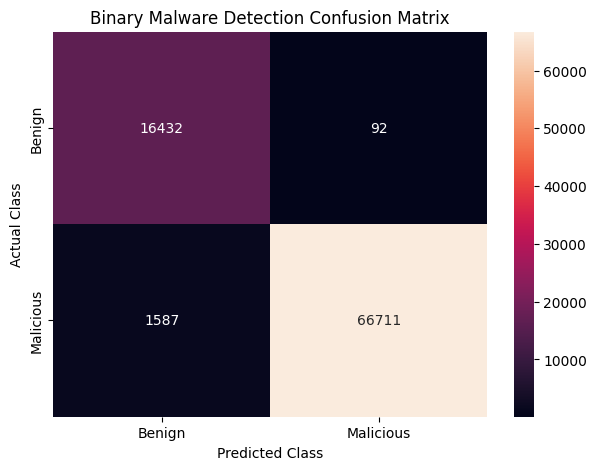

In [47]:
# Create a confusion matrix
from sklearn.metrics import confusion_matrix
binary_cm = confusion_matrix(y_binary_test, binary_pred)
plt.figure(figsize=(7, 5))
sns.heatmap(
    binary_cm,
    annot=True,
    fmt="d",
    xticklabels=["Benign", "Malicious"],
    yticklabels=["Benign", "Malicious"]
)

plt.title("Binary Malware Detection Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.show()

In [48]:
# Create a simple function for malware detection

def detect_traffic(sample):

    sample_scaled = scaler.transform(sample)

    probability = binary_model.predict(sample_scaled, verbose=0)[0][0]

    if probability >= 0.5:
        prediction = "MALICIOUS"
        confidence = probability * 100
    else:
        prediction = "BENIGN"
        confidence = (1 - probability) * 100

    print("Prediction:", prediction)
    print("Confidence:", round(confidence, 2), "%")

In [49]:
# Test the detector using one sample from the test dataset
sample = X_test.iloc[[0]]
detect_traffic(sample)

Prediction: MALICIOUS
Confidence: 100.0 %


In [50]:
# Find a benign sample and test it
benign_index = y_binary_test[y_binary_test == 0].index[0]
sample = X.loc[[benign_index]]
detect_traffic(sample)

AttributeError: 'numpy.ndarray' object has no attribute 'index'

In [51]:
# Find a benign sample from the test dataset
benign_position = np.where(y_binary_test == 0)[0][0]
sample = X_test.iloc[[benign_position]]
detect_traffic(sample)

Prediction: BENIGN
Confidence: 95.6 %


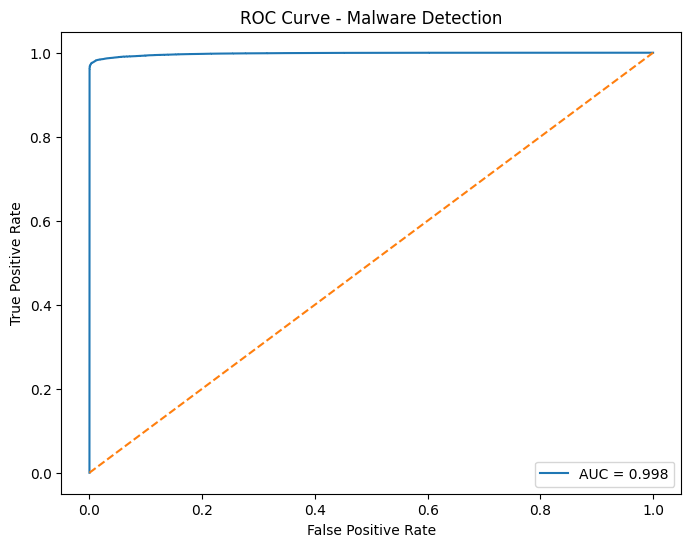

ROC-AUC Score: 0.9979768335000845


In [52]:
# Plot the ROC curve for the binary classifier
from sklearn.metrics import roc_curve, roc_auc_score
fpr, tpr, thresholds = roc_curve(
    y_binary_test,
    binary_pred_prob
)

auc_score = roc_auc_score(
    y_binary_test,
    binary_pred_prob
)

plt.figure(figsize=(8, 6))

plt.plot(fpr, tpr, label=f"AUC = {auc_score:.3f}")

plt.plot([0, 1], [0, 1], linestyle="--")

plt.title("ROC Curve - Malware Detection")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()

plt.show()

print("ROC-AUC Score:", auc_score)

In [53]:
# Function to detect whether network traffic is benign or malicious

def detect_traffic(sample):

    # Scale the input using the same scaler used during training
    sample_scaled = scaler.transform(sample)

    # Get the prediction probability
    probability = binary_model.predict(sample_scaled, verbose=0)[0][0]

    # Convert probability into a class
    if probability >= 0.5:
        prediction = "MALICIOUS"
        confidence = probability * 100
    else:
        prediction = "BENIGN"
        confidence = (1 - probability) * 100

    print("Prediction:", prediction)
    print("Confidence: {:.2f}%".format(confidence))

In [54]:
# Test one malicious traffic sample

malicious_position = np.where(y_binary_test == 1)[0][0]

malicious_sample = X_test.iloc[[malicious_position]]

detect_traffic(malicious_sample)

Prediction: MALICIOUS
Confidence: 100.00%


In [55]:
# Simple menu for testing the malware detector

print("AI CYBER THREAT DETECTOR")
print("------")
print("1. Test a benign sample")
print("2. Test a malicious sample")

choice = input("Enter your choice (1 or 2): ")

if choice == "1":
    position = np.where(y_binary_test == 0)[0][0]
    sample = X_test.iloc[[position]]
    print("\nTesting benign network traffic...")
    detect_traffic(sample)

elif choice == "2":
    position = np.where(y_binary_test == 1)[0][0]
    sample = X_test.iloc[[position]]
    print("\nTesting malicious network traffic...")
    detect_traffic(sample)

else:
    print("Invalid choice. Please enter 1 or 2.")

AI CYBER THREAT DETECTOR
------
1. Test a benign sample
2. Test a malicious sample
Enter your choice (1 or 2): 2

Testing malicious network traffic...
Prediction: MALICIOUS
Confidence: 100.00%


In [56]:
# Create a simple interactive cybersecurity detector

import ipywidgets as widgets
from IPython.display import display

# Create the title
title = widgets.HTML(
    "<h2>🛡️ AI Cyber Threat Detector</h2>"
)

# Create a dropdown for selecting traffic type
sample_choice = widgets.Dropdown(
    options=[
        ("Benign Traffic", 0),
        ("Malicious Traffic", 1)
    ],
    description="Traffic:"
)

# Create the button
button = widgets.Button(
    description="Analyze Traffic"
)

# Create an area to display the result
result = widgets.Output()

def analyze_traffic(button):
    with result:
        result.clear_output()

        position = np.where(
            y_binary_test == sample_choice.value
        )[0][0]

        sample = X_test.iloc[[position]]

        sample_scaled = scaler.transform(sample)

        probability = binary_model.predict(
            sample_scaled,
            verbose=0
        )[0][0]

        if probability >= 0.5:
            prediction = "MALICIOUS"
            confidence = probability * 100
        else:
            prediction = "BENIGN"
            confidence = (1 - probability) * 100

        print("Network Traffic Analysis")
        print("------------------------")
        print("Prediction:", prediction)
        print("Confidence: {:.2f}%".format(confidence))

button.on_click(analyze_traffic)

display(title)
display(sample_choice)
display(button)
display(result)

HTML(value='<h2>🛡️ AI Cyber Threat Detector</h2>')

Dropdown(description='Traffic:', options=(('Benign Traffic', 0), ('Malicious Traffic', 1)), value=0)

Button(description='Analyze Traffic', style=ButtonStyle())

Output()

In [57]:
# Final performance summary of the AI Cyber Threat Detector

print("AI CYBER THREAT DETECTOR - FINAL RESULTS")
print("=" * 45)

print("Test Accuracy : {:.2f}%".format(binary_test_accuracy * 100))
print("ROC-AUC Score : {:.4f}".format(0.9979768335))

print("\nModel Performance:")
print("Benign Precision   : 0.91")
print("Benign Recall      : 0.99")
print("Malicious Precision: 1.00")
print("Malicious Recall   : 0.98")

print("\nSystem Status: Model trained and tested successfully.")

AI CYBER THREAT DETECTOR - FINAL RESULTS
Test Accuracy : 98.02%
ROC-AUC Score : 0.9980

Model Performance:
Benign Precision   : 0.91
Benign Recall      : 0.99
Malicious Precision: 1.00
Malicious Recall   : 0.98

System Status: Model trained and tested successfully.


In [58]:
# Save the trained deep learning model

binary_model.save("cyber_threat_detector.keras")

print("Model saved successfully!")

Model saved successfully!
